# Pertemuan 5 — Visualisasi, KPI, dan Data Storytelling

Minggu lalu data penjualan sudah dibersihkan dan diringkas jadi tabel. Hari ini angka dan tabel itu diubah jadi **grafik**, lalu diceritakan jadi **insight**.

Dataset: `data-bersih.csv` (hasil cleaning pertemuan 4). Upload dulu ke Colab lewat panel Files di sebelah kiri.

## 0. Kenalan Dulu: 4 Jenis Grafik di Data Kecil

Sebelum pakai data penjualan asli, kita coba dulu di data mini biar gampang dilihat.

- **Bar chart** — membandingkan kategori.

- **Line chart** — melihat perubahan dari waktu ke waktu.

- **Histogram** — melihat sebaran angka.

- **Scatter plot** — melihat hubungan dua angka.

### Bar chart: grafik jelek dulu, lalu dirapikan

Grafik pertama sengaja dibuat tanpa judul dan label. Coba tebak: ini grafik apa, satuannya apa?

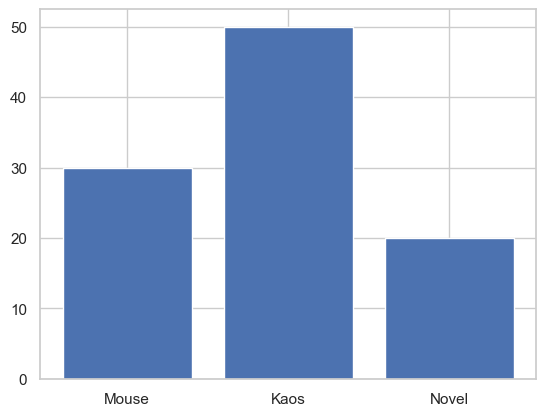

In [53]:
import matplotlib.pyplot as plt

produk = ["Mouse", "Kaos", "Novel"]
terjual = [30, 50, 20]

plt.bar(produk, terjual)
plt.show()

Sekarang data yang sama, tapi sudah ada judul, label sumbu, dan satuan.

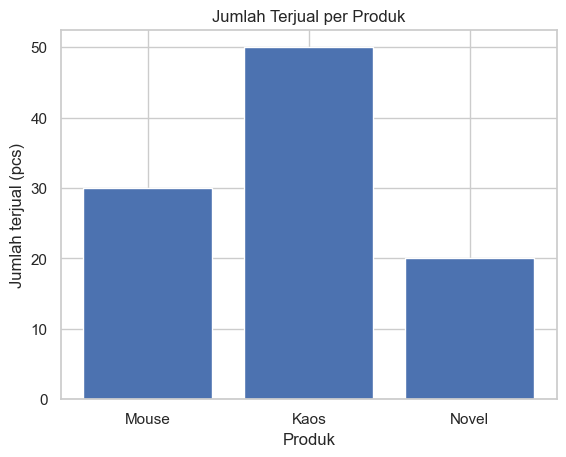

In [54]:
plt.bar(produk, terjual)
plt.title("Jumlah Terjual per Produk")
plt.xlabel("Produk")
plt.ylabel("Jumlah terjual (pcs)")
plt.show()

### Line chart: perubahan dari waktu ke waktu

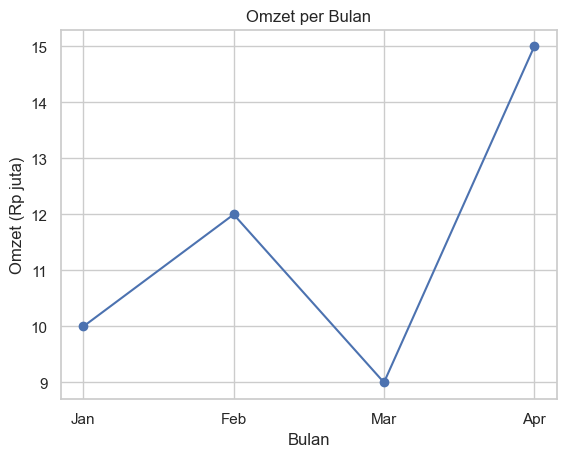

In [55]:
bulan = ["Jan", "Feb", "Mar", "Apr"]
omzet = [10, 12, 9, 15]

plt.plot(bulan, omzet, marker="o")
plt.title("Omzet per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Omzet (Rp juta)")
plt.show()

### Histogram: seberapa tersebar angkanya

Tiap batang menghitung ada berapa data di rentang angka tertentu.

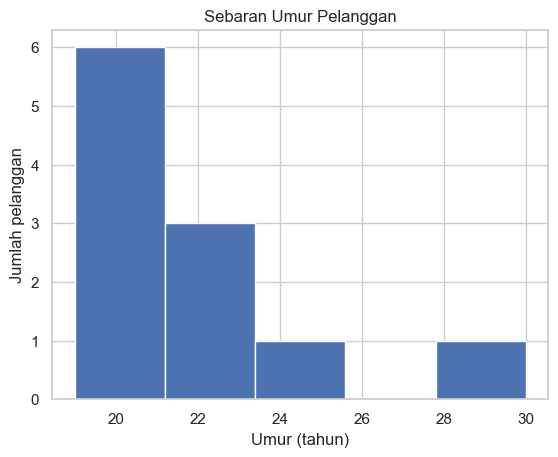

In [56]:
umur = [19, 20, 20, 21, 21, 21, 22, 22, 23, 25, 30]

plt.hist(umur, bins=5)
plt.title("Sebaran Umur Pelanggan")
plt.xlabel("Umur (tahun)")
plt.ylabel("Jumlah pelanggan")
plt.show()

### Scatter plot: apakah dua angka saling berhubungan?

Tiap titik = satu data. Di sini: makin lama belajar, makin tinggi nilainya?

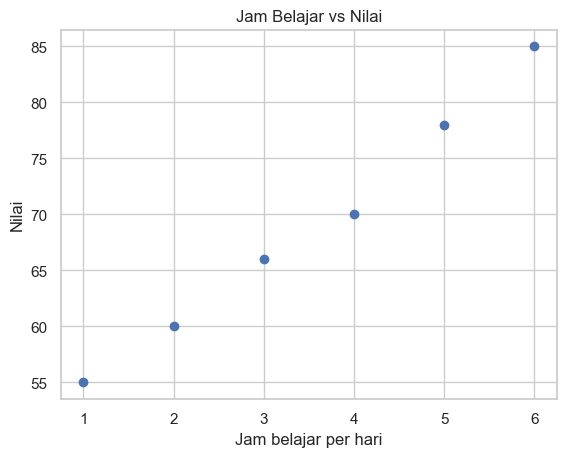

In [57]:
jam_belajar = [1, 2, 3, 4, 5, 6]
nilai = [55, 60, 66, 70, 78, 85]

plt.scatter(jam_belajar, nilai)
plt.title("Jam Belajar vs Nilai")
plt.xlabel("Jam belajar per hari")
plt.ylabel("Nilai")
plt.show()

Itu empat jenis grafik dasarnya. Sekarang kita pakai ke data penjualan yang asli.

## 0b. Cara Kerja Library (Contoh Simple)

Bagian ini bahan belajar tambahan. Tidak memakai data penjualan, cuma data kecil biar gampang dilihat. Tujuannya satu: paham **cara kerja** Matplotlib, Seaborn, dan Plotly sebelum dipakai di data yang besar.

- **Matplotlib** — pondasinya. Semua grafik digambar "tangan sendiri" langkah demi langkah.

- **Seaborn** — dibangun di atas Matplotlib, lebih ringkas untuk tabel (DataFrame).

- **Plotly** — hasilnya grafik interaktif yang bisa di-hover dan di-zoom.

### Matplotlib: Figure dan Axes

Bayangkan menggambar di atas kertas. **Figure** itu kertasnya, **Axes** itu kotak gambar di atas kertas (tempat sumbu, garis, dan batang digambar). Satu kertas bisa berisi beberapa kotak gambar.

Ada dua gaya menulis, hasilnya sama:

- **Gaya `plt.`** — Matplotlib otomatis memakai "kotak yang sedang aktif". Enak untuk satu grafik.

- **Gaya `ax.`** — kita sendiri yang memegang kotak gambarnya. Wajib kalau mau beberapa grafik berdampingan.

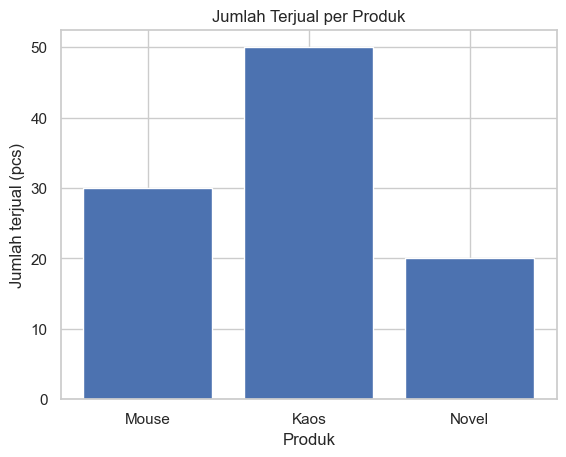

In [58]:
import matplotlib.pyplot as plt

produk = ["Mouse", "Kaos", "Novel"]
terjual = [30, 50, 20]

# Gaya plt: gambar dulu, hiasi, baru tampilkan
plt.bar(produk, terjual)
plt.title("Jumlah Terjual per Produk")
plt.xlabel("Produk")
plt.ylabel("Jumlah terjual (pcs)")
plt.show()

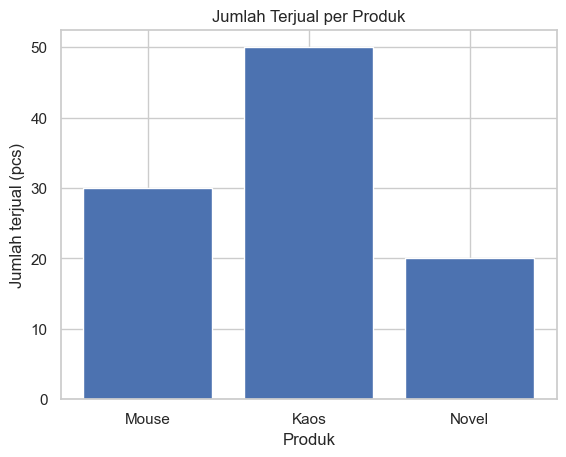

In [59]:
# Gaya ax: sama persis hasilnya, tapi kita pegang kotak gambarnya (ax)
fig, ax = plt.subplots()
ax.bar(produk, terjual)
ax.set_title("Jumlah Terjual per Produk")
ax.set_xlabel("Produk")
ax.set_ylabel("Jumlah terjual (pcs)")
plt.show()

Perhatikan namanya: `plt.title(...)` berubah jadi `ax.set_title(...)`, `plt.xlabel(...)` jadi `ax.set_xlabel(...)`. Polanya selalu sama.

### Dua garis dalam satu grafik + legend

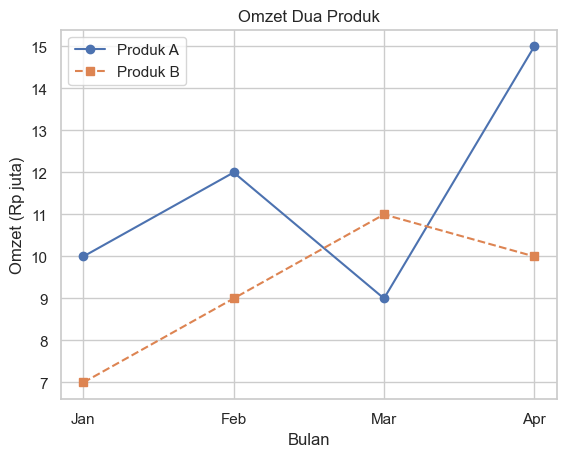

In [60]:
bulan = ["Jan", "Feb", "Mar", "Apr"]
omzet_a = [10, 12, 9, 15]
omzet_b = [7, 9, 11, 10]

# label= dipakai legend() untuk menamai tiap garis
plt.plot(bulan, omzet_a, marker="o", linestyle="-", label="Produk A")
plt.plot(bulan, omzet_b, marker="s", linestyle="--", label="Produk B")
plt.title("Omzet Dua Produk")
plt.xlabel("Bulan")
plt.ylabel("Omzet (Rp juta)")
plt.legend()
plt.show()

### Scatter: ukuran dan warna titik

`s=` mengatur ukuran titik, `c=` warna, `alpha=` transparansi (0 sampai 1) supaya titik yang bertumpuk tetap kelihatan.

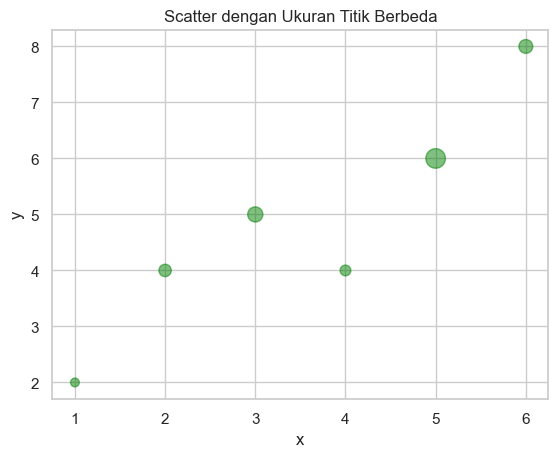

In [61]:
x = [1, 2, 3, 4, 5, 6]
y = [2, 4, 5, 4, 6, 8]
ukuran = [40, 80, 120, 60, 200, 100]

plt.scatter(x, y, s=ukuran, c="green", alpha=0.5)
plt.title("Scatter dengan Ukuran Titik Berbeda")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

### Histogram: `bins` itu jumlah "keranjang"

Histogram mengelompokkan angka ke dalam rentang. `bins` menentukan berapa rentangnya: sedikit = kasar, banyak = detail.

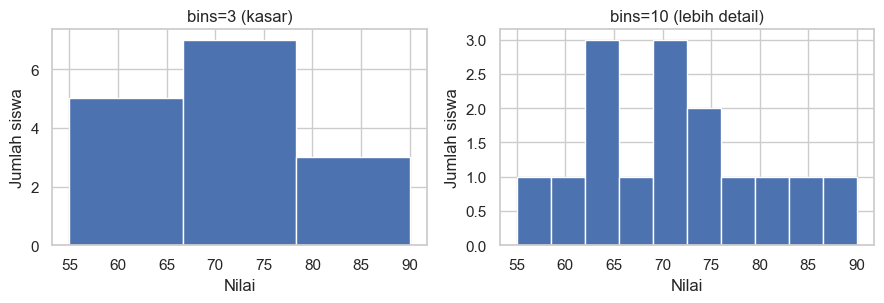

In [62]:
nilai_ujian = [55, 60, 62, 65, 65, 68, 70, 70, 72, 75, 75, 78, 80, 85, 90]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(9, 3.2))

kiri.hist(nilai_ujian, bins=3)
kiri.set_title("bins=3 (kasar)")

kanan.hist(nilai_ujian, bins=10)
kanan.set_title("bins=10 (lebih detail)")

for ax in (kiri, kanan):
    ax.set_xlabel("Nilai")
    ax.set_ylabel("Jumlah siswa")

plt.tight_layout()
plt.show()

### Pie chart: `autopct` menampilkan persen

Pie chart cuma cocok untuk **2–4 bagian** dari satu keseluruhan.

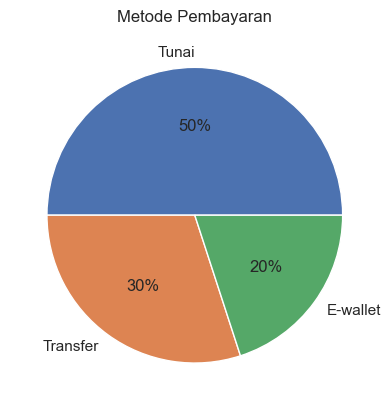

In [63]:
metode = ["Tunai", "Transfer", "E-wallet"]
porsi_bayar = [50, 30, 20]

plt.pie(porsi_bayar, labels=metode, autopct="%1.0f%%")
plt.title("Metode Pembayaran")
plt.show()

### Dua grafik berdampingan: `subplots`

`plt.subplots(1, 2)` artinya 1 baris, 2 kolom. `suptitle` memberi judul untuk seluruh kertas, `tight_layout()` merapikan jarak supaya tidak bertumpuk.

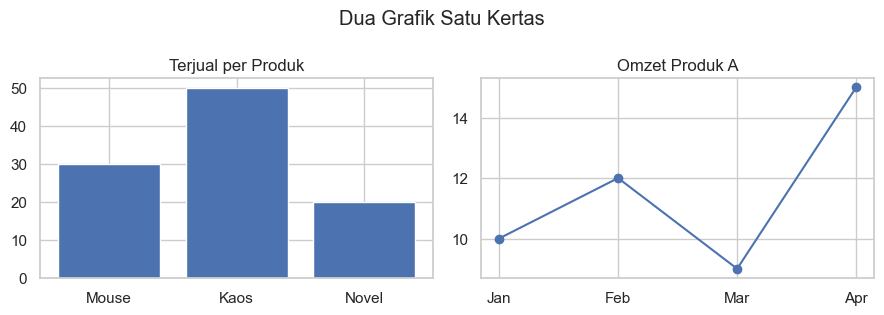

In [64]:
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(9, 3.2))

kiri.bar(produk, terjual)
kiri.set_title("Terjual per Produk")

kanan.plot(bulan, omzet_a, marker="o")
kanan.set_title("Omzet Produk A")

fig.suptitle("Dua Grafik Satu Kertas")
plt.tight_layout()
plt.show()

### Hiasan yang paling sering dipakai

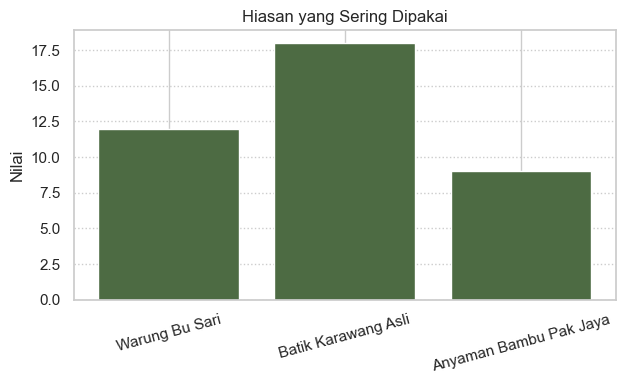

In [65]:
nama_toko = ["Warung Bu Sari", "Batik Karawang Asli", "Anyaman Bambu Pak Jaya"]
nilai_toko = [12, 18, 9]

plt.figure(figsize=(7, 3.5))                       # ukuran gambar (lebar, tinggi)
plt.bar(nama_toko, nilai_toko, color="#4d6b43")    # warna batang
plt.xticks(rotation=15)                            # miringkan label yang panjang
plt.grid(axis="y", linestyle=":")                  # garis bantu horizontal
plt.title("Hiasan yang Sering Dipakai")
plt.ylabel("Nilai")
plt.savefig("grafik_contoh.png", dpi=150, bbox_inches="tight")   # simpan jadi file
plt.show()

### Seaborn: bekerja dengan tabel yang rapi

Seaborn paham **DataFrame**. Syaratnya, tabelnya "rapi": satu baris = satu kejadian, satu kolom = satu hal yang dicatat. Kita cukup menyebut nama tabel dan nama kolom, Seaborn yang mengurus sisanya, termasuk **menghitung ringkasan sendiri**.

In [66]:
import pandas as pd
import seaborn as sns

toy = pd.DataFrame({
    "kota": ["Jakarta", "Jakarta", "Bandung", "Bandung", "Bandung", "Medan", "Medan", "Jakarta"],
    "kategori": ["Makanan", "Buku", "Makanan", "Buku", "Makanan", "Buku", "Makanan", "Makanan"],
    "penjualan": [30, 12, 25, 10, 28, 8, 22, 35],
})
display(toy)

,kota,kategori,penjualan
0,Jakarta,Makanan,30
1,Jakarta,Buku,12
2,Bandung,Makanan,25
3,Bandung,Buku,10
4,Bandung,Makanan,28
5,Medan,Buku,8
6,Medan,Makanan,22
7,Jakarta,Makanan,35


### `barplot` vs `countplot`: dua-duanya batang, tugasnya beda

- **`barplot`** — tinggi batang = **rata-rata** kolom angka (`y`) per kelompok.

- **`countplot`** — tinggi batang = **jumlah baris** per kelompok. Tidak butuh `y`.

`errorbar=None` mematikan garis kecil di ujung batang (rentang kepercayaan) supaya grafik tidak membingungkan di awal.

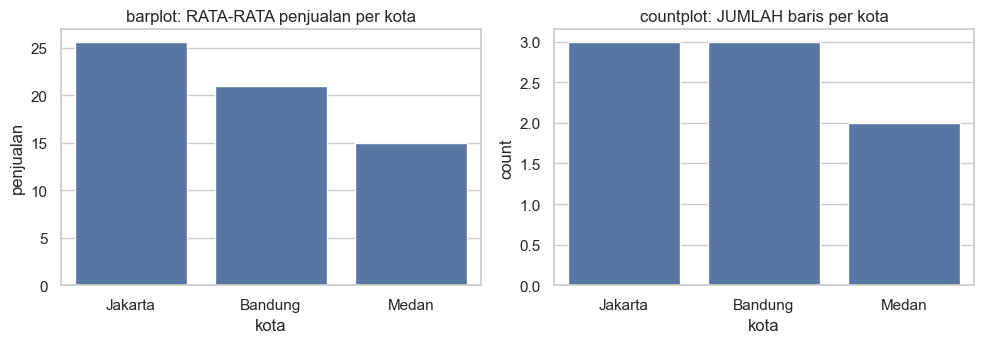

In [67]:
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.6))

sns.barplot(data=toy, x="kota", y="penjualan", errorbar=None, ax=kiri)
kiri.set_title("barplot: RATA-RATA penjualan per kota")

sns.countplot(data=toy, x="kota", ax=kanan)
kanan.set_title("countplot: JUMLAH baris per kota")

plt.tight_layout()
plt.show()

### `hue` dan `palette`: pecah per kelompok

`hue="kategori"` memecah batang jadi beberapa warna sesuai isi kolom itu, lengkap dengan legend otomatis. `palette` memilih kumpulan warnanya.

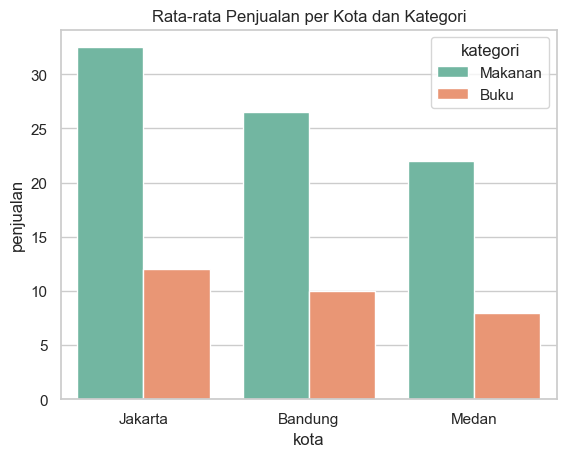

In [68]:
sns.barplot(data=toy, x="kota", y="penjualan", hue="kategori",
            errorbar=None, palette="Set2")
plt.title("Rata-rata Penjualan per Kota dan Kategori")
plt.show()

### `histplot` dengan `kde=True`: sebaran + garis halus

`kde=True` menambah garis mulus yang menunjukkan "bentuk" sebarannya.

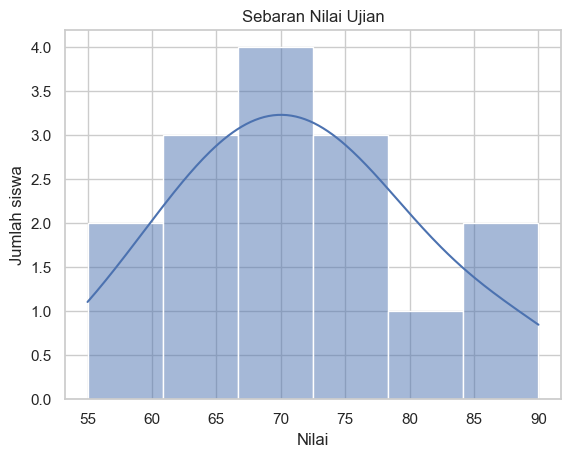

In [69]:
sns.histplot(nilai_ujian, bins=6, kde=True)
plt.title("Sebaran Nilai Ujian")
plt.xlabel("Nilai")
plt.ylabel("Jumlah siswa")
plt.show()

### `boxplot` per kelompok

Kotak = separuh data di tengah (Q1 sampai Q3), garis di dalam kotak = median. Cocok untuk membandingkan sebaran antar kelompok.

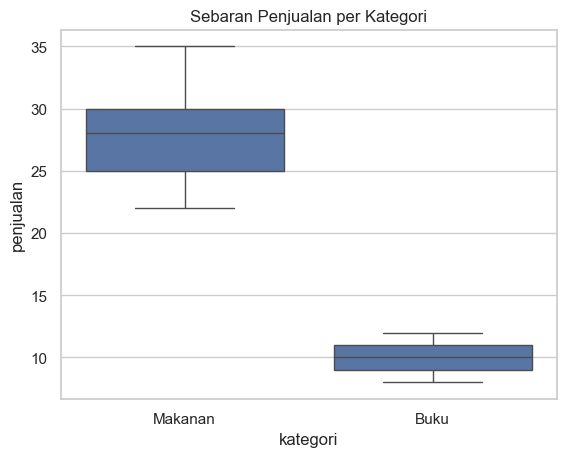

In [70]:
sns.boxplot(data=toy, x="kategori", y="penjualan")
plt.title("Sebaran Penjualan per Kategori")
plt.show()

### `set_theme`: ganti tampilan dengan satu baris

Satu baris di awal mengubah tampilan semua grafik sesudahnya. Di akhir contoh ini tampilan dikembalikan ke bawaan supaya tidak mengganggu bagian berikutnya.

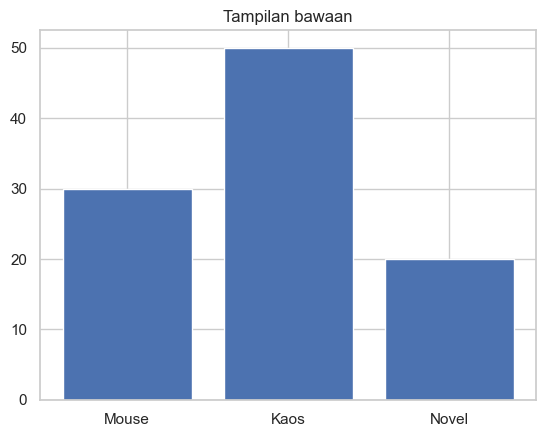

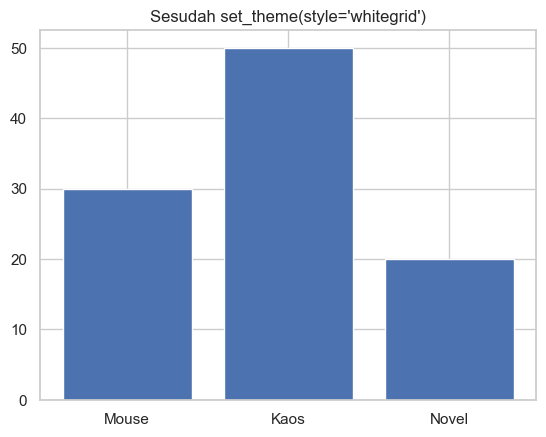

In [71]:
# Tampilan bawaan Matplotlib
plt.bar(produk, terjual)
plt.title("Tampilan bawaan")
plt.show()

# Satu baris, tampilan berubah untuk semua grafik sesudahnya
sns.set_theme(style="whitegrid")
plt.bar(produk, terjual)
plt.title("Sesudah set_theme(style='whitegrid')")
plt.show()

sns.reset_defaults()   # kembalikan ke tampilan bawaan

### Plotly: grafik yang "hidup"

Cara kerja Plotly beda dari Matplotlib. `px.bar(...)` tidak menggambar langsung. Dia membuat sebuah **objek `Figure`**: catatan berisi data dan gaya grafik. Objek itu lalu digambar oleh **plotly.js di browser**, itulah kenapa grafiknya bisa di-hover dan di-zoom.

- `fig.show()` — menampilkan di notebook.

- `fig.write_html("nama.html")` — menyimpan jadi halaman web yang tetap interaktif, bisa dikirim ke orang lain.

- Pola kodenya sama seperti Seaborn: tabel, kolom X, kolom Y.

In [72]:
import plotly.express as px

toy_p = pd.DataFrame({
    "produk": ["Mouse", "Kaos", "Novel", "Topi"],
    "terjual": [30, 50, 20, 35],
})

fig = px.bar(toy_p, x="produk", y="terjual", title="Jumlah Terjual per Produk")
fig.show()

### `px.line` dengan `color=`: banyak garis sekaligus

`color="produk"` otomatis membuat satu garis per isi kolom `produk`, lengkap dengan legend.

In [73]:
omzet_df = pd.DataFrame({
    "bulan": ["Jan", "Feb", "Mar"] * 2,
    "produk": ["A"] * 3 + ["B"] * 3,
    "omzet": [10, 12, 9, 7, 9, 11],
})

fig = px.line(omzet_df, x="bulan", y="omzet", color="produk", markers=True,
              title="Omzet per Bulan")
fig.show()

### `px.scatter`: `size` dan `hover_data`

`size` membuat besar titik mengikuti sebuah kolom. `hover_name` dan `hover_data` menambah info yang muncul saat kursor diarahkan ke titik.

In [74]:
produk_df = pd.DataFrame({
    "nama": ["Mouse", "Kaos", "Novel", "Topi", "Tas"],
    "harga": [150, 75, 60, 40, 220],
    "rating": [4.5, 4.0, 4.8, 3.9, 4.2],
    "stok": [20, 50, 10, 35, 15],
})

fig = px.scatter(produk_df, x="harga", y="rating", size="stok",
                 hover_name="nama", hover_data=["stok"],
                 title="Harga vs Rating (besar titik = stok)")
fig.show()

### Mengatur tampilan: `update_layout` dan `update_traces`

- `update_traces(...)` — mengatur **isi grafik** (warna batang, garis).

- `update_layout(...)` — mengatur **kerangka grafik** (judul, label sumbu, ukuran).

In [75]:
fig = px.bar(toy_p, x="produk", y="terjual")
fig.update_traces(marker_color="#4d6b43")
fig.update_layout(
    title="Jumlah Terjual per Produk",
    xaxis_title="Produk",
    yaxis_title="Jumlah terjual (pcs)",
)
fig.write_html("grafik_interaktif.html")   # simpan jadi halaman web
fig.show()

### Jenis grafik lain yang sering dipakai: `px.histogram` dan `px.pie`

In [76]:
fig = px.histogram(x=nilai_ujian, nbins=6, title="Sebaran Nilai Ujian")
fig.update_layout(xaxis_title="Nilai", yaxis_title="Jumlah siswa")
fig.show()

fig = px.pie(names=metode, values=porsi_bayar, title="Metode Pembayaran")
fig.show()

### Satu grafik, tiga library

Bar chart yang sama dibuat di ketiga library. Hasilnya mirip, bedanya di cara menulis dan sifat hasilnya (gambar diam atau interaktif).

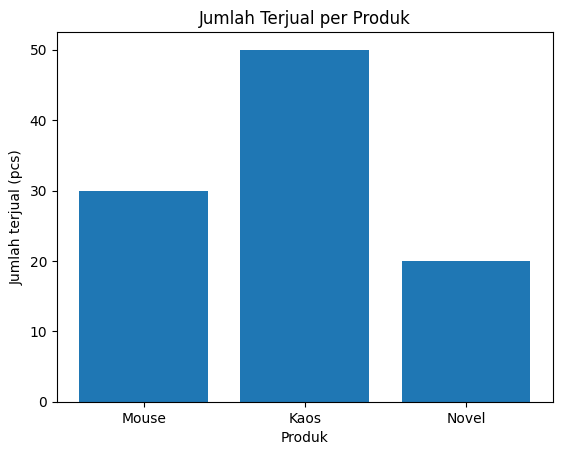

In [77]:
# Matplotlib: gambar sendiri, hiasi sendiri
plt.bar(produk, terjual)
plt.title("Jumlah Terjual per Produk")
plt.xlabel("Produk")
plt.ylabel("Jumlah terjual (pcs)")
plt.show()

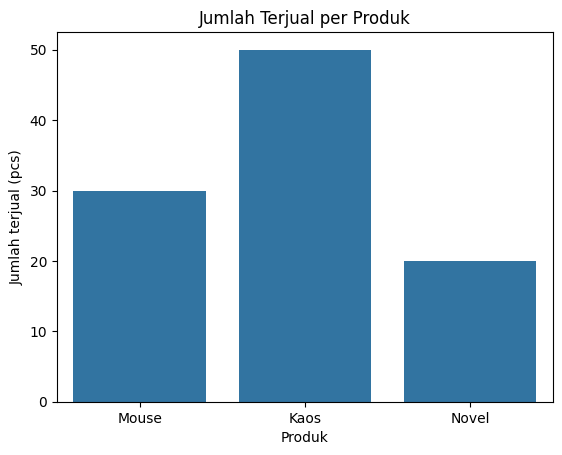

In [78]:
# Seaborn: sebut tabel dan kolomnya, judul tetap lewat plt
tabel = pd.DataFrame({"produk": produk, "terjual": terjual})

sns.barplot(data=tabel, x="produk", y="terjual")
plt.title("Jumlah Terjual per Produk")
plt.xlabel("Produk")
plt.ylabel("Jumlah terjual (pcs)")
plt.show()

In [79]:
# Plotly: satu baris, judul dan label di dalam px, hasilnya interaktif
fig = px.bar(tabel, x="produk", y="terjual", title="Jumlah Terjual per Produk",
             labels={"produk": "Produk", "terjual": "Jumlah terjual (pcs)"})
fig.show()

| Mau apa | Pakai | Alasan |
|---|---|---|
| Belajar dasar, atau butuh kontrol penuh atas gambar | Matplotlib | Semua bisa diatur, tapi kodenya lebih panjang |
| Analisis cepat dari DataFrame | Seaborn | Ringkas, tampilan enak, ada `hue` dan statistik otomatis |
| Dashboard atau presentasi online | Plotly | Interaktif, bisa disimpan jadi HTML |

## 0c. Grafik Mana untuk Masalah Apa

Tidak semua grafik bisa dipakai untuk semua masalah. Tiap grafik punya **tugas** sendiri. Salah pilih, datanya benar tapi pembaca jadi salah paham.

### Kenali dulu jenis datanya

| Jenis data | Contoh di data penjualan | Ciri |
|---|---|---|
| **Kategori** | kategori produk, wilayah | Teks yang mengelompokkan |
| **Angka** | harga, jumlah, untung | Bisa dijumlah atau dirata-rata |
| **Waktu** | tanggal, bulan | Punya urutan dari lama ke baru |

### Tiga pertanyaan sebelum memilih grafik

1. **Apa yang mau dijawab?** Membandingkan, melihat tren, melihat sebaran, melihat hubungan, atau melihat porsi?

2. **Jenis data apa yang kupunya?** Kategori, angka, atau waktu?

3. **Siapa pembacanya?** Yang awam butuh yang sederhana.

Di bawah ini enam masalah. Tiap masalah punya dua grafik berdampingan: **kiri kurang tepat**, **kanan tepat**.

### Masalah 1: Membandingkan kategori → bar chart

**Pertanyaan:** "Kategori mana yang paling besar penjualannya?"

Garis (line chart) menghubungkan titik-titik, jadi menyiratkan ada **urutan** dari satu titik ke titik berikutnya. Antar kategori tidak ada urutan seperti itu.

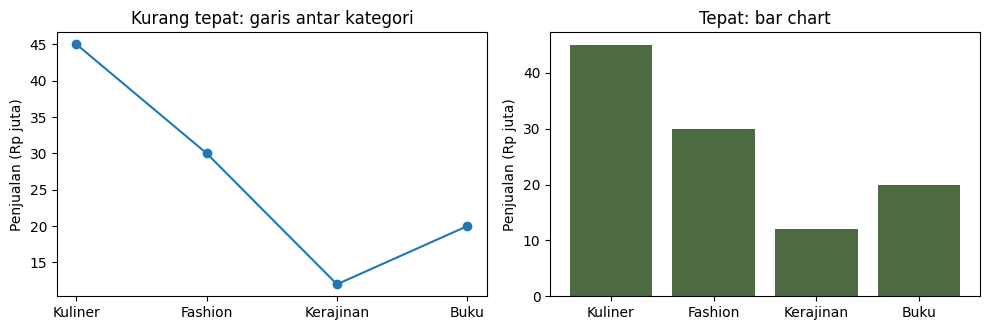

In [80]:
kategori = ["Kuliner", "Fashion", "Kerajinan", "Buku"]
nilai_kat = [45, 30, 12, 20]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.4))

kiri.plot(kategori, nilai_kat, marker="o")
kiri.set_title("Kurang tepat: garis antar kategori")

kanan.bar(kategori, nilai_kat, color="#4d6b43")
kanan.set_title("Tepat: bar chart")

for ax in (kiri, kanan):
    ax.set_ylabel("Penjualan (Rp juta)")

plt.tight_layout()
plt.show()

### Masalah 2: Melihat tren waktu → line chart

**Pertanyaan:** "Penjualan naik atau turun dari bulan ke bulan?"

Pie chart menjawab "porsi", bukan "naik atau turun". Dengan 6 irisan, tren hampir mustahil dibaca.

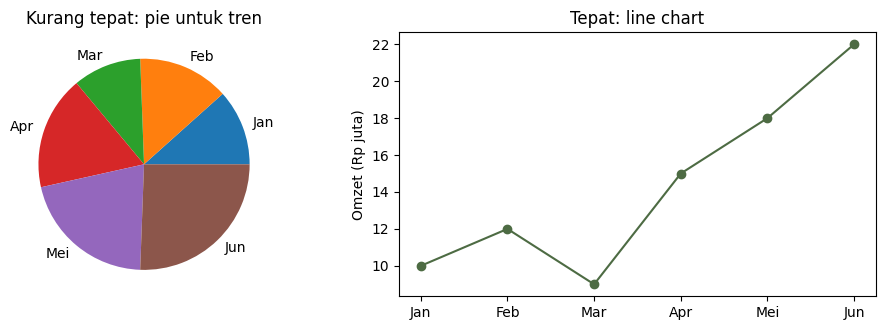

In [81]:
bulan_enam = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun"]
omzet_enam = [10, 12, 9, 15, 18, 22]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.4))

kiri.pie(omzet_enam, labels=bulan_enam)
kiri.set_title("Kurang tepat: pie untuk tren")

kanan.plot(bulan_enam, omzet_enam, marker="o", color="#4d6b43")
kanan.set_title("Tepat: line chart")
kanan.set_ylabel("Omzet (Rp juta)")

plt.tight_layout()
plt.show()

### Masalah 3: Melihat sebaran angka → histogram

**Pertanyaan:** "Nilai siswa kebanyakan ada di rentang berapa?"

Bar chart per orang menampilkan setiap nilai satu-satu. Untuk 20 orang saja sudah ramai, dan kita tetap sulit melihat "bentuk" sebarannya.

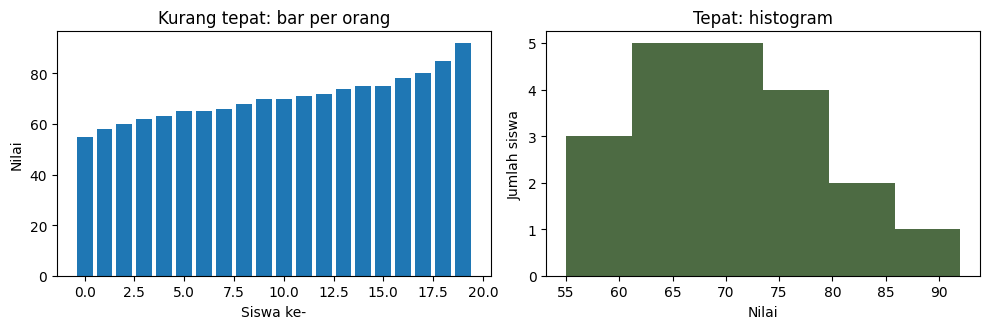

In [82]:
nilai_20 = [55, 58, 60, 62, 63, 65, 65, 66, 68, 70,
            70, 71, 72, 74, 75, 75, 78, 80, 85, 92]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.4))

kiri.bar(range(len(nilai_20)), nilai_20)
kiri.set_title("Kurang tepat: bar per orang")
kiri.set_xlabel("Siswa ke-")
kiri.set_ylabel("Nilai")

kanan.hist(nilai_20, bins=6, color="#4d6b43")
kanan.set_title("Tepat: histogram")
kanan.set_xlabel("Nilai")
kanan.set_ylabel("Jumlah siswa")

plt.tight_layout()
plt.show()

### Masalah 4: Membandingkan sebaran antar kelompok → boxplot

**Pertanyaan:** "Kelas A dan kelas B, mana yang lebih merata nilainya?"

Bar chart rata-rata menyembunyikan sebaran. Di contoh ini dua kelas **rata-ratanya sama persis**, tapi isinya sangat beda.

Rata-rata kelas A: 50.0
Rata-rata kelas B: 50.0


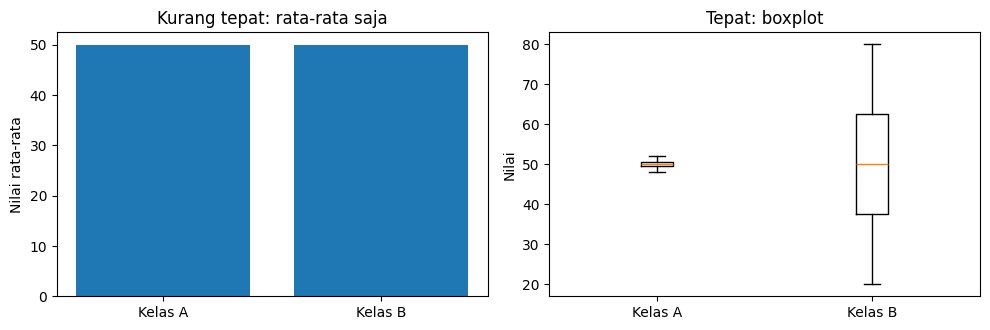

In [83]:
kelas_a = [48, 49, 50, 50, 50, 51, 52]      # nilai berkumpul di sekitar 50
kelas_b = [20, 30, 45, 50, 55, 70, 80]      # nilai tersebar jauh

rata_a = sum(kelas_a) / len(kelas_a)
rata_b = sum(kelas_b) / len(kelas_b)
print("Rata-rata kelas A:", rata_a)
print("Rata-rata kelas B:", rata_b)

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.4))

kiri.bar(["Kelas A", "Kelas B"], [rata_a, rata_b])
kiri.set_title("Kurang tepat: rata-rata saja")
kiri.set_ylabel("Nilai rata-rata")

kanan.boxplot([kelas_a, kelas_b], tick_labels=["Kelas A", "Kelas B"])
kanan.set_title("Tepat: boxplot")
kanan.set_ylabel("Nilai")

plt.tight_layout()
plt.show()

### Masalah 5: Melihat hubungan dua angka → scatter plot

**Pertanyaan:** "Apakah makin besar biaya iklan, makin besar penjualan?"

Garis yang menghubungkan titik-titik akan zig-zag dan menyiratkan ada urutan, padahal yang kita cari adalah **pola sebarannya**.

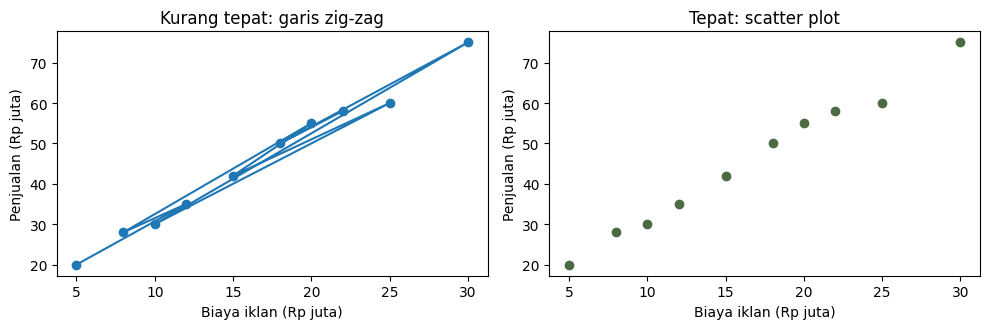

In [84]:
iklan = [5, 12, 8, 20, 15, 25, 10, 30, 18, 22]
penjualan_iklan = [20, 35, 28, 55, 42, 60, 30, 75, 50, 58]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.4))

kiri.plot(iklan, penjualan_iklan, marker="o")
kiri.set_title("Kurang tepat: garis zig-zag")

kanan.scatter(iklan, penjualan_iklan, color="#4d6b43")
kanan.set_title("Tepat: scatter plot")

for ax in (kiri, kanan):
    ax.set_xlabel("Biaya iklan (Rp juta)")
    ax.set_ylabel("Penjualan (Rp juta)")

plt.tight_layout()
plt.show()

### Masalah 6: Melihat porsi → pie chart (kalau sedikit) atau bar chart

**Pertanyaan:** "Dari seluruh penjualan, tiap bagian kebagian berapa persen?"

Pie chart baik untuk **2–4 bagian** (lihat contoh metode pembayaran di atas). Kalau bagiannya banyak, irisan kecil tidak bisa dibandingkan dan labelnya bertumpuk. Pakai bar chart yang diurutkan.

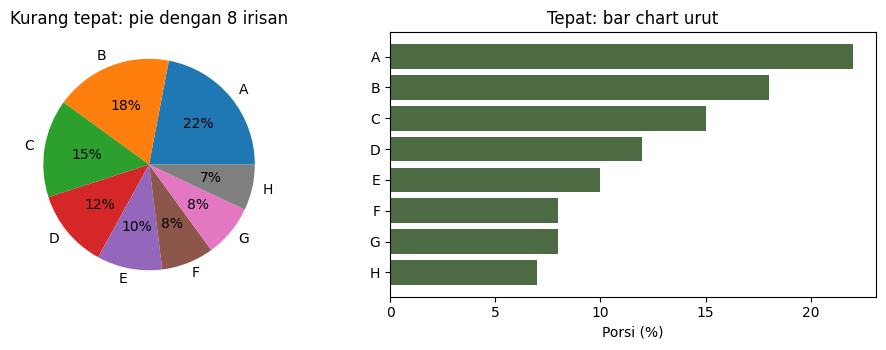

In [85]:
produk_8 = ["A", "B", "C", "D", "E", "F", "G", "H"]
porsi_8 = [22, 18, 15, 12, 10, 8, 8, 7]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(10, 3.6))

kiri.pie(porsi_8, labels=produk_8, autopct="%1.0f%%")
kiri.set_title("Kurang tepat: pie dengan 8 irisan")

kanan.barh(produk_8[::-1], porsi_8[::-1], color="#4d6b43")
kanan.set_title("Tepat: bar chart urut")
kanan.set_xlabel("Porsi (%)")

plt.tight_layout()
plt.show()

### Ringkasannya

| Masalah | Grafik | Data yang dibutuhkan | Jangan dipakai kalau |
|---|---|---|---|
| Membandingkan kategori | Bar chart | 1 kategori + 1 angka | Datanya urutan waktu |
| Tren dari waktu ke waktu | Line chart | waktu + angka | Sumbu X bukan urutan (kategori acak) |
| Sebaran satu angka | Histogram | 1 angka | Mau membandingkan kategori |
| Sebaran antar kelompok, atau cari outlier | Boxplot | angka + kategori | Data per kelompok sangat sedikit |
| Hubungan dua angka | Scatter plot | 2 angka | Salah satunya bukan angka |
| Porsi dari satu keseluruhan | Pie chart | 2–4 bagian | Bagian banyak, atau tidak menjumlah ke satu keseluruhan |
| Pola di tabel dua dimensi, korelasi | Heatmap | tabel kategori × kategori atau angka | Datanya cuma satu dimensi |

## 1. Baca Data dan Siapkan Kolom

Perhatikan tipe kolom `tanggal` setelah dibaca. Ingat pertemuan 4: file CSV hanya menyimpan teks, jadi tipe tanggalnya hilang dan harus diubah lagi.

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("data-bersih.csv")
print(df["tanggal"].dtype)

df["tanggal"] = pd.to_datetime(df["tanggal"])
df["bulan"] = df["tanggal"].dt.to_period("M").astype(str)

print(df.shape)
display(df.head())

object
(129, 11)


,id_pesanan,tanggal,nama_produk,kategori,harga,jumlah,wilayah,modal,nilai_penjualan,untung,bulan
0,1001,2026-01-05,Mouse,Elektronik,150000.0,2,Jakarta,95000,300000.0,110000.0,2026-01
1,1002,2026-01-29,Mouse,Elektronik,155000.0,2,Bandung,113000,310000.0,84000.0,2026-01
2,1003,2026-01-12,Speaker Bluetooth,Elektronik,313000.0,5,Karawang,196000,1565000.0,585000.0,2026-01
3,1004,2026-01-30,Novel Fiksi,Buku,62000.0,2,Karawang,39000,124000.0,46000.0,2026-01
4,1005,2026-02-23,Matras Yoga,Olahraga,121000.0,5,Bandung,71000,605000.0,250000.0,2026-02


## 2. Siapkan Tabel Ringkasan

Dua tabel ini sama seperti pertemuan 4. Bedanya, sekarang ditambah kolom dalam **juta rupiah** supaya angka di grafik tidak kepanjangan.

In [87]:
ringkasan = (
    df.groupby("kategori", as_index=False)
      .agg(total_penjualan=("nilai_penjualan", "sum"),
           jumlah_transaksi=("id_pesanan", "nunique"))
      .sort_values("total_penjualan", ascending=False)
)
ringkasan["total_juta"] = ringkasan["total_penjualan"] / 1_000_000

df_bulanan = df.groupby("bulan", as_index=False).agg(
    total_penjualan=("nilai_penjualan", "sum")
)
df_bulanan["total_juta"] = df_bulanan["total_penjualan"] / 1_000_000

# kolom bantu dalam satuan ribu, dipakai di histogram dan scatter plot
df["harga_ribu"] = df["harga"] / 1000
df["modal_ribu"] = df["modal"] / 1000

# dua warna saja: satu warna utama, satu warna untuk menyorot
warna_utama = "#4d6b43"
warna_sorot = "#c9a66b"

display(ringkasan)
display(df_bulanan)

,kategori,total_penjualan,jumlah_transaksi,total_juta
1,Elektronik,44893000.0,24,44.893
2,Fashion,15775000.0,27,15.775
4,Olahraga,7913000.0,26,7.913
0,Buku,3948000.0,29,3.948
3,Makanan,3275000.0,23,3.275


,bulan,total_penjualan,total_juta
0,2026-01,42775000.0,42.775
1,2026-02,18240000.0,18.240
2,2026-03,14789000.0,14.789


## 3. Grafik Pertama (Sengaja Jelek)

Ini grafik yang paling gampang ditulis. Lihat sendiri apa yang kurang.

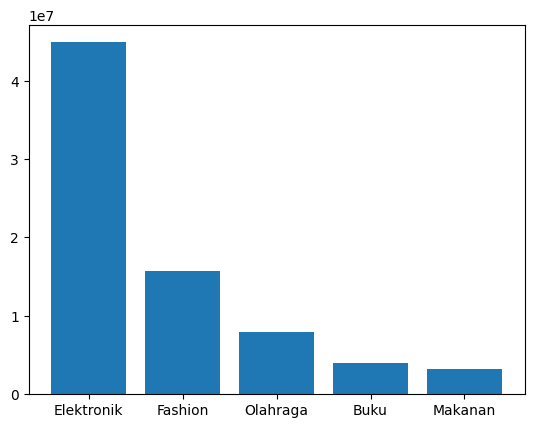

In [88]:
plt.bar(ringkasan["kategori"], ringkasan["total_penjualan"])
plt.show()

## 4. Perbaiki Jadi Bar Chart yang Rapi

Yang diperbaiki: judul, label sumbu, satuan juta rupiah, urutan besar ke kecil, dan satu warna sorot untuk kategori terbesar.

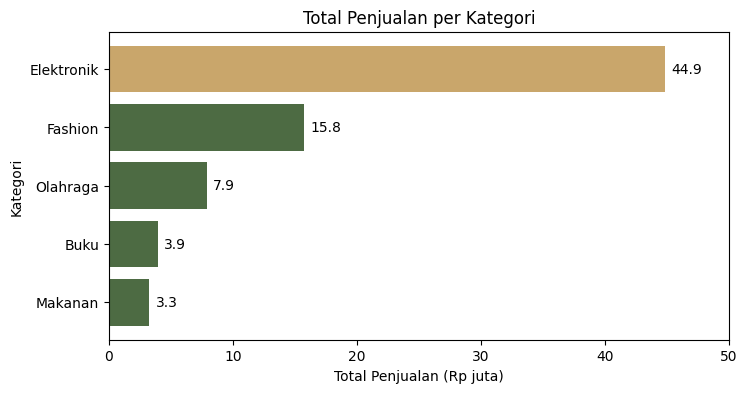

In [89]:
urut = ringkasan.sort_values("total_juta")  # barh menggambar dari bawah, jadi urut kecil ke besar
terbesar = ringkasan.iloc[0]["kategori"]
warna = [warna_sorot if k == terbesar else warna_utama for k in urut["kategori"]]

plt.figure(figsize=(8, 4))
plt.barh(urut["kategori"], urut["total_juta"], color=warna)
plt.title("Total Penjualan per Kategori")
plt.xlabel("Total Penjualan (Rp juta)")
plt.ylabel("Kategori")
plt.xlim(0, 50)  # beri ruang di kanan supaya angka di ujung batang tidak terpotong

for i, nilai in enumerate(urut["total_juta"]):
    plt.text(nilai + 0.5, i, f"{nilai:.1f}", va="center")

plt.show()

**Versi interaktif.** Data dan tampilannya sama, tapi arahkan kursor ke batang untuk melihat angka persisnya.

In [90]:
fig = px.bar(urut, x="total_juta", y="kategori", orientation="h", color="kategori",
             color_discrete_sequence=warna, text="total_juta", range_x=[0, 50],
             title="Total Penjualan per Kategori")
fig.update_traces(texttemplate="%{x:.1f}", textposition="outside")
fig.update_layout(xaxis_title="Total Penjualan (Rp juta)", yaxis_title="Kategori",
                  showlegend=False)
fig.show()

## 5. Pie Chart vs Bar Chart

Data yang sama, dua grafik. Mana yang lebih gampang dibandingkan?

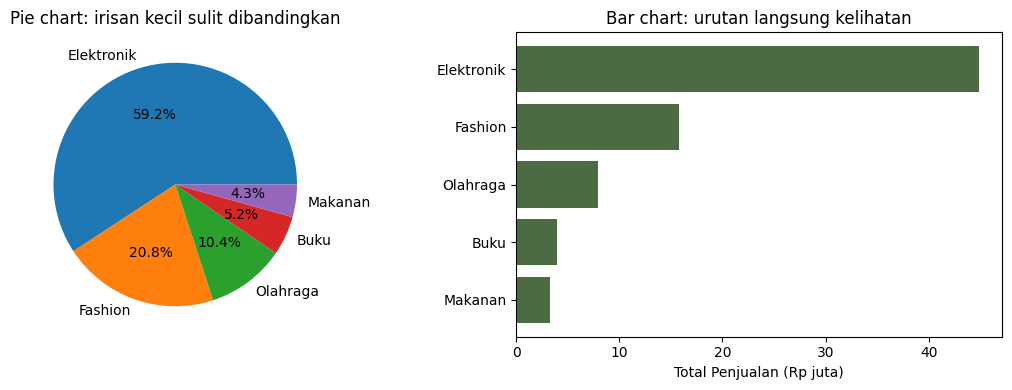

In [91]:
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(11, 4))

kiri.pie(ringkasan["total_juta"], labels=ringkasan["kategori"], autopct="%1.1f%%")
kiri.set_title("Pie chart: irisan kecil sulit dibandingkan")

kanan.barh(urut["kategori"], urut["total_juta"], color=warna_utama)
kanan.set_title("Bar chart: urutan langsung kelihatan")
kanan.set_xlabel("Total Penjualan (Rp juta)")

plt.tight_layout()
plt.show()

**Versi interaktif.** Pie chart yang sama di Plotly. Arahkan kursor ke irisan untuk melihat persennya, klik nama di legend untuk menyembunyikan satu kategori.

In [92]:
fig = px.pie(ringkasan, names="kategori", values="total_juta",
             title="Porsi Penjualan per Kategori")
fig.show()

## 6. Line Chart: Tren Penjualan per Bulan

Sumbu Y dimulai dari 0 supaya penurunan tidak terlihat lebih dramatis dari kenyataan.

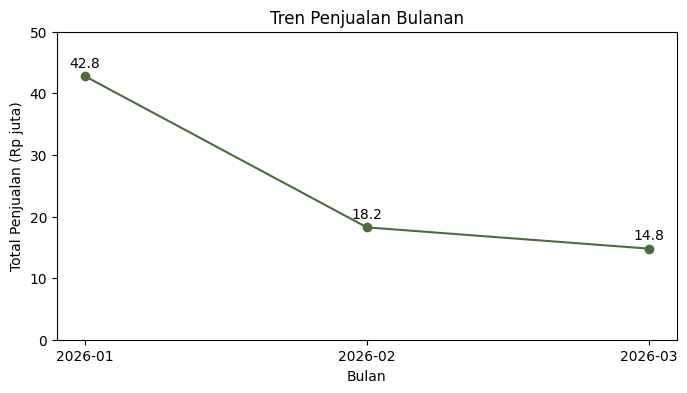

In [93]:
plt.figure(figsize=(8, 4))
plt.plot(df_bulanan["bulan"], df_bulanan["total_juta"], marker="o", color=warna_utama)
plt.title("Tren Penjualan Bulanan")
plt.xlabel("Bulan")
plt.ylabel("Total Penjualan (Rp juta)")
plt.ylim(0, 50)

for i, nilai in enumerate(df_bulanan["total_juta"]):
    plt.text(i, nilai + 1.5, f"{nilai:.1f}", ha="center")

plt.show()

## 7. Histogram: Sebaran Harga

Kiri: semua data. Kanan: tanpa satu harga yang jauh di luar kebiasaan.

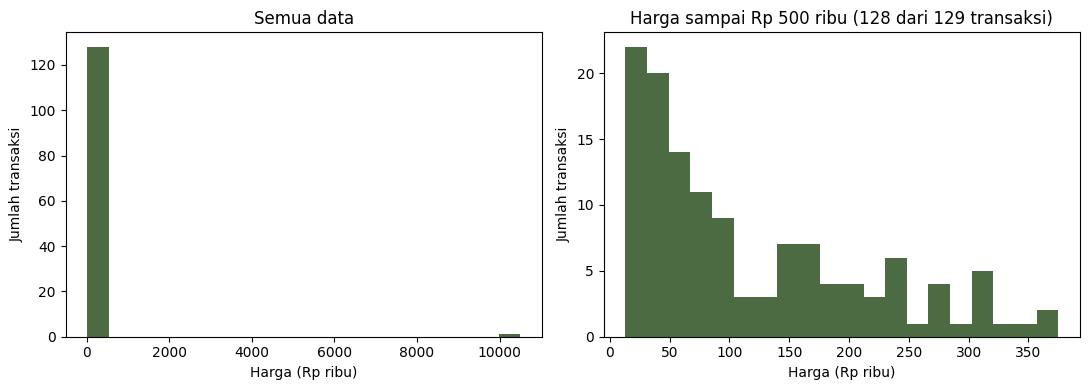

In [94]:
biasa = df[df["harga"] <= 500000]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(11, 4))

kiri.hist(df["harga_ribu"], bins=20, color=warna_utama)
kiri.set_title("Semua data")

kanan.hist(biasa["harga_ribu"], bins=20, color=warna_utama)
kanan.set_title(f"Harga sampai Rp 500 ribu ({len(biasa)} dari {len(df)} transaksi)")

for ax in (kiri, kanan):
    ax.set_xlabel("Harga (Rp ribu)")
    ax.set_ylabel("Jumlah transaksi")

plt.tight_layout()
plt.show()

**Versi interaktif.** Dua histogram yang sama. Arahkan kursor ke batang untuk melihat rentang harga dan jumlah transaksinya.

In [95]:
fig = px.histogram(df, x="harga_ribu", nbins=20, color_discrete_sequence=[warna_utama],
                   title="Sebaran Harga: Semua Data")
fig.update_layout(xaxis_title="Harga (Rp ribu)", yaxis_title="Jumlah transaksi")
fig.show()

fig = px.histogram(biasa, x="harga_ribu", nbins=20, color_discrete_sequence=[warna_utama],
                   title="Sebaran Harga: Sampai Rp 500 ribu")
fig.update_layout(xaxis_title="Harga (Rp ribu)", yaxis_title="Jumlah transaksi")
fig.show()

## 8. Boxplot dengan Seaborn

Mulai di sini kita pakai **Seaborn**. Boxplot adalah gambar dari aturan IQR di pertemuan 4: kotak = Q1 sampai Q3, titik di luar garis = outlier.

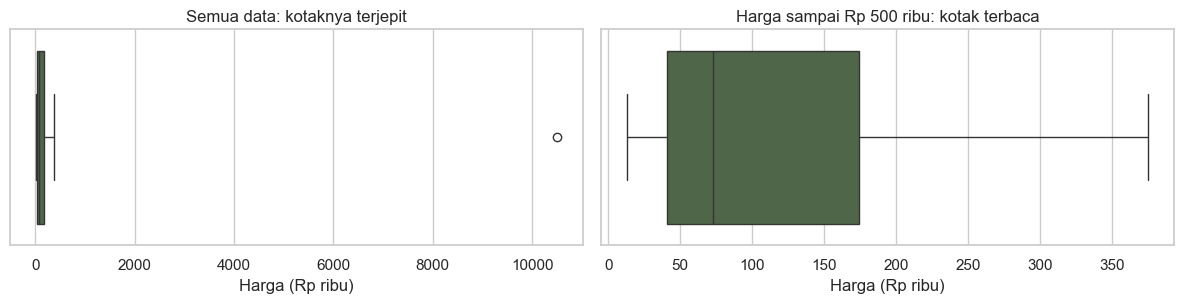

Batas atas IQR: 378500.0
Jumlah titik di atas batas: 1


In [96]:
sns.set_theme(style="whitegrid")

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12, 3.2))

sns.boxplot(x=df["harga_ribu"], color=warna_utama, ax=kiri)
kiri.set_title("Semua data: kotaknya terjepit")

sns.boxplot(x=biasa["harga_ribu"], color=warna_utama, ax=kanan)
kanan.set_title("Harga sampai Rp 500 ribu: kotak terbaca")

for ax in (kiri, kanan):
    ax.set_xlabel("Harga (Rp ribu)")

plt.tight_layout()
plt.show()

q1 = df["harga"].quantile(0.25)
q3 = df["harga"].quantile(0.75)
batas_atas = q3 + 1.5 * (q3 - q1)
print("Batas atas IQR:", batas_atas)
print("Jumlah titik di atas batas:", (df["harga"] > batas_atas).sum())

**Versi interaktif.** Arahkan kursor ke titik outlier: nama produknya langsung muncul (`hover_name`). Di boxplot Plotly, hover di kotak menampilkan Q1, median, Q3.

In [97]:
fig = px.box(df, x="harga_ribu", points="outliers", hover_name="nama_produk",
             color_discrete_sequence=[warna_utama], title="Boxplot Harga: Semua Data")
fig.update_layout(xaxis_title="Harga (Rp ribu)")
fig.show()

fig = px.box(biasa, x="harga_ribu", points="outliers", hover_name="nama_produk",
             color_discrete_sequence=[warna_utama], title="Boxplot Harga: Sampai Rp 500 ribu")
fig.update_layout(xaxis_title="Harga (Rp ribu)")
fig.show()

## 9. Scatter Plot: Harga vs Modal

Titik di atas garis putus-putus = untung. Titik di bawahnya = rugi (harga jual lebih rendah dari modal).

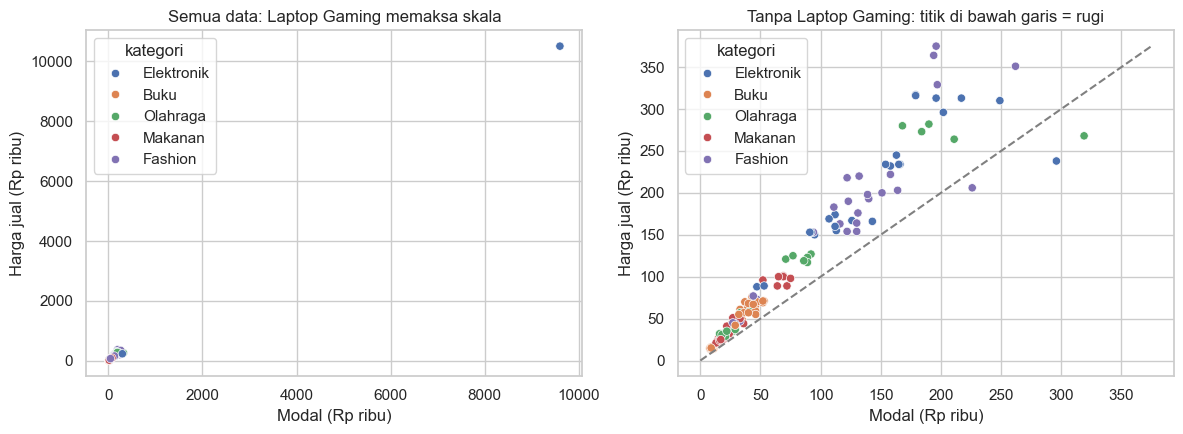

Jumlah transaksi rugi: 3


In [98]:
tanpa_laptop = df[df["nama_produk"] != "Laptop Gaming (Bonus)"]

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(data=df, x="modal_ribu", y="harga_ribu", hue="kategori", ax=kiri)
kiri.set_title("Semua data: Laptop Gaming memaksa skala")

sns.scatterplot(data=tanpa_laptop, x="modal_ribu", y="harga_ribu", hue="kategori", ax=kanan)
batas = tanpa_laptop[["modal_ribu", "harga_ribu"]].max().max()
kanan.plot([0, batas], [0, batas], "--", color="gray")  # garis impas: harga = modal
kanan.set_title("Tanpa Laptop Gaming: titik di bawah garis = rugi")

for ax in (kiri, kanan):
    ax.set_xlabel("Modal (Rp ribu)")
    ax.set_ylabel("Harga jual (Rp ribu)")

plt.tight_layout()
plt.show()

print("Jumlah transaksi rugi:", (df["untung"] < 0).sum())

**Versi interaktif (semua data).** Titik Laptop Gaming yang menjauh bisa langsung diarahkan kursornya. Coba zoom ke kumpulan titik di kiri bawah (tarik kotak dengan mouse) untuk melihat pola yang tadinya terjepit.

In [99]:
fig = px.scatter(df, x="modal_ribu", y="harga_ribu", color="kategori",
                 hover_name="nama_produk", title="Harga vs Modal: Semua Data")
fig.update_layout(xaxis_title="Modal (Rp ribu)", yaxis_title="Harga jual (Rp ribu)")
fig.show()

## 10. Bar Chart Versi Seaborn

Hasilnya mirip langkah 4, tapi kodenya lebih pendek karena kita cukup menyebut nama tabel dan kolom.

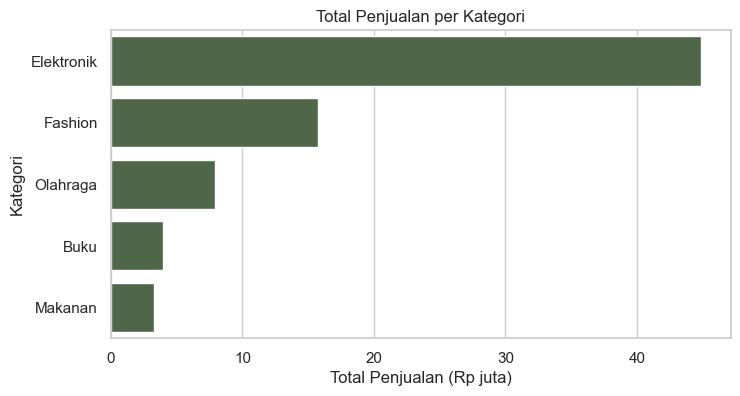

In [100]:
plt.figure(figsize=(8, 4))
sns.barplot(data=ringkasan, x="total_juta", y="kategori", color=warna_utama)
plt.title("Total Penjualan per Kategori")
plt.xlabel("Total Penjualan (Rp juta)")
plt.ylabel("Kategori")
plt.show()

## 11. Heatmap: Tabel yang Diberi Warna

Ini `pivot_table` wilayah × kategori dari pertemuan 4. Makin pekat warnanya, makin besar angkanya. Angkanya juga ditulis di tiap kotak.

kategori,Buku,Elektronik,Fashion,Makanan,Olahraga
wilayah,,,,,
Bandung,0.8,35.2,1.3,0.3,1.1
Jakarta,0.4,2.4,5.7,1.0,1.6
Karawang,0.3,2.0,4.5,0.7,1.8
Medan,0.7,3.8,3.4,0.4,1.8
Surabaya,1.7,1.5,0.9,0.9,1.7


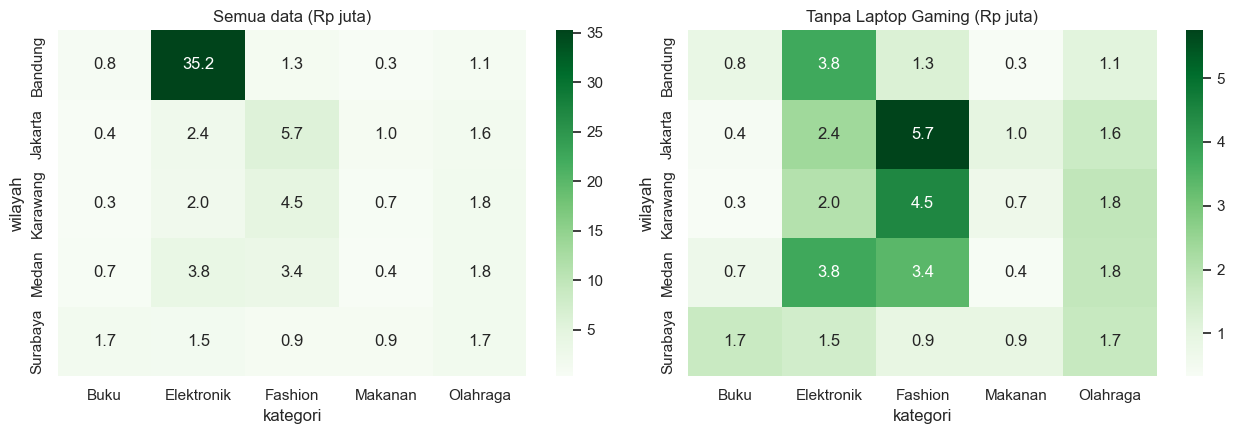

In [101]:
pivot = pd.pivot_table(df, values="nilai_penjualan", index="wilayah",
                       columns="kategori", aggfunc="sum", fill_value=0) / 1_000_000
pivot_tanpa = pd.pivot_table(tanpa_laptop, values="nilai_penjualan", index="wilayah",
                             columns="kategori", aggfunc="sum", fill_value=0) / 1_000_000

display(pivot.round(1))

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Greens", ax=kiri)
kiri.set_title("Semua data (Rp juta)")

sns.heatmap(pivot_tanpa, annot=True, fmt=".1f", cmap="Greens", ax=kanan)
kanan.set_title("Tanpa Laptop Gaming (Rp juta)")

plt.tight_layout()
plt.show()

**Versi interaktif.** Arahkan kursor ke kotak untuk melihat wilayah, kategori, dan nilainya. `px.imshow` mengubah tabel jadi heatmap, `text_auto` menuliskan angkanya.

In [102]:
fig = px.imshow(pivot, text_auto=".1f", color_continuous_scale="Greens", aspect="auto",
                title="Penjualan wilayah x kategori: semua data (Rp juta)")
fig.show()

fig = px.imshow(pivot_tanpa, text_auto=".1f", color_continuous_scale="Greens", aspect="auto",
                title="Penjualan wilayah x kategori: tanpa Laptop Gaming (Rp juta)")
fig.show()

## 12. Heatmap Korelasi

Korelasi mengukur seberapa kompak dua angka bergerak bareng. Skalanya -1 sampai 1: dekat 1 = naik bareng, dekat 0 = tidak berhubungan, dekat -1 = yang satu naik yang lain turun.

,harga,jumlah,modal,nilai_penjualan,untung
harga,1.00,-0.00,1.00,1.00,0.89
jumlah,-0.00,1.00,-0.00,0.06,0.21
modal,1.00,-0.00,1.00,1.00,0.87
nilai_penjualan,1.00,0.06,1.00,1.00,0.91
untung,0.89,0.21,0.87,0.91,1.00


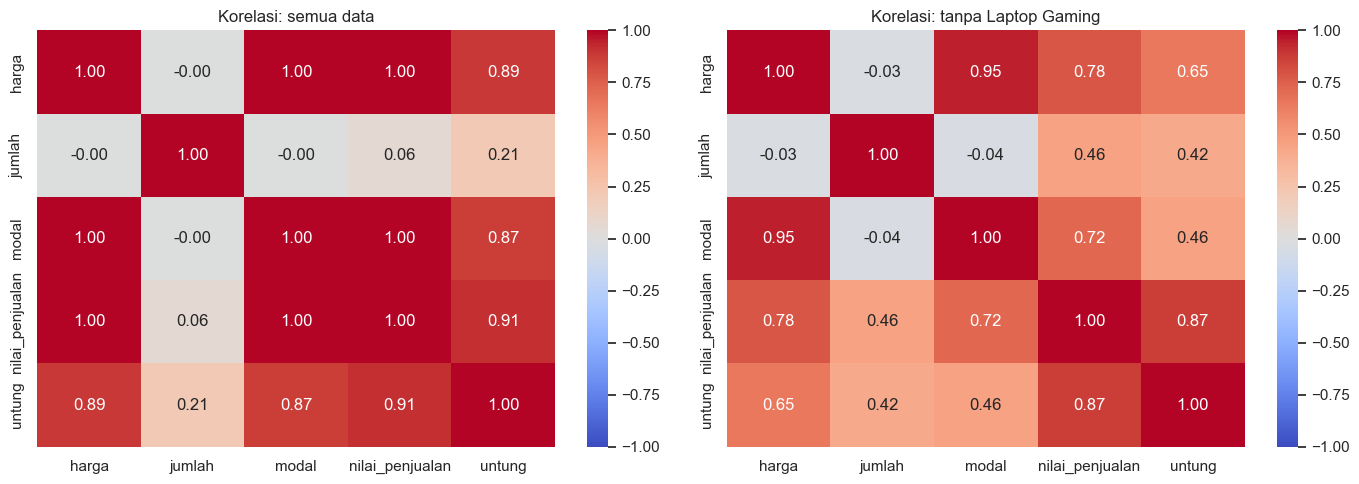

In [103]:
kolom = ["harga", "jumlah", "modal", "nilai_penjualan", "untung"]

display(df[kolom].corr().round(2))

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df[kolom].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=kiri)
kiri.set_title("Korelasi: semua data")

sns.heatmap(tanpa_laptop[kolom].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=kanan)
kanan.set_title("Korelasi: tanpa Laptop Gaming")

plt.tight_layout()
plt.show()

**Versi interaktif.** Skala warna dikunci -1 sampai 1 (`zmin`, `zmax`), sama seperti `vmin`/`vmax` di Seaborn.

In [104]:
fig = px.imshow(df[kolom].corr(), text_auto=".2f", color_continuous_scale="RdBu_r",
                zmin=-1, zmax=1, title="Korelasi: semua data")
fig.show()

fig = px.imshow(tanpa_laptop[kolom].corr(), text_auto=".2f", color_continuous_scale="RdBu_r",
                zmin=-1, zmax=1, title="Korelasi: tanpa Laptop Gaming")
fig.show()

## 13. Plotly: Grafik Interaktif

Plotly menghasilkan grafik yang bisa di-hover (muncul angkanya) dan di-zoom. Coba arahkan kursor ke titik-titiknya.

In [105]:
fig = px.line(df_bulanan, x="bulan", y="total_juta", markers=True,
              range_y=[0, 50], title="Tren Penjualan Bulanan")
fig.update_xaxes(type="category")  # "2026-01" itu teks, jangan dianggap tanggal oleh Plotly
fig.update_layout(xaxis_title="Bulan", yaxis_title="Total Penjualan (Rp juta)")
fig.show()

## 14. Plotly: Scatter dengan Nama Produk

`hover_name` membuat nama produk muncul saat kursor diarahkan ke titik.

In [106]:
fig = px.scatter(tanpa_laptop, x="modal", y="harga", color="kategori",
                 hover_name="nama_produk", title="Harga vs Modal (tanpa Laptop Gaming)")
fig.update_layout(xaxis_title="Modal (Rp)", yaxis_title="Harga jual (Rp)")
fig.show()

## 15. KPI: Angka yang Membantu Keputusan

Empat KPI untuk data penjualan ini. Rata-rata nilai pesanan = total penjualan dibagi jumlah pesanan.

In [107]:
def format_rupiah(angka):
    return "Rp " + f"{angka:,.0f}".replace(",", ".")

total_revenue = df["nilai_penjualan"].sum()
jumlah_transaksi = df["id_pesanan"].nunique()
rata_nilai_pesanan = total_revenue / jumlah_transaksi

kpi = pd.DataFrame({
    "KPI": ["Total revenue", "Jumlah transaksi", "Rata-rata nilai pesanan"],
    "Nilai": [format_rupiah(total_revenue), jumlah_transaksi, format_rupiah(rata_nilai_pesanan)],
})
display(kpi)

df_bulanan["pertumbuhan_%"] = (df_bulanan["total_penjualan"].pct_change() * 100).round(1)
display(df_bulanan[["bulan", "total_juta", "pertumbuhan_%"]])

,KPI,Nilai
0,Total revenue,Rp 75.804.000
1,Jumlah transaksi,129
2,Rata-rata nilai pesanan,Rp 587.628


,bulan,total_juta,pertumbuhan_%
0,2026-01,42.775,NaN
1,2026-02,18.240,-57.4
2,2026-03,14.789,-18.9


## 16. Porsi Penjualan vs Porsi Transaksi

Kategori yang paling besar penjualannya belum tentu yang paling sering dibeli.

,kategori,porsi_penjualan,porsi_transaksi
1,Elektronik,59.2,18.6
2,Fashion,20.8,20.9
4,Olahraga,10.4,20.2
0,Buku,5.2,22.5
3,Makanan,4.3,17.8


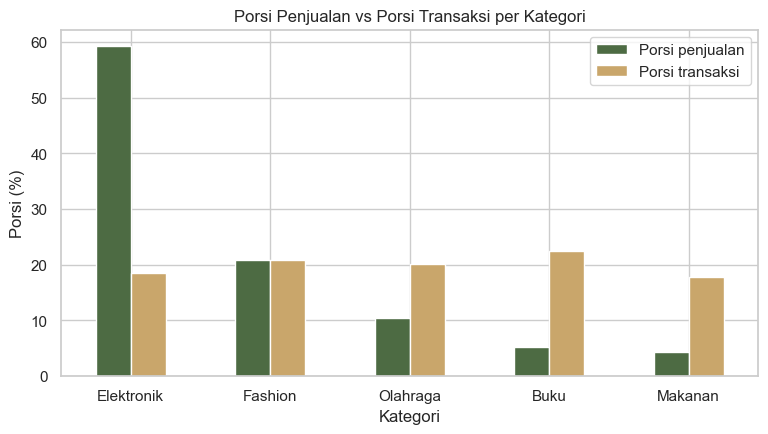

In [108]:
porsi = ringkasan.copy()
porsi["porsi_penjualan"] = porsi["total_penjualan"] / porsi["total_penjualan"].sum() * 100
porsi["porsi_transaksi"] = porsi["jumlah_transaksi"] / porsi["jumlah_transaksi"].sum() * 100

display(porsi[["kategori", "porsi_penjualan", "porsi_transaksi"]].round(1))

porsi.set_index("kategori")[["porsi_penjualan", "porsi_transaksi"]].plot(
    kind="bar", figsize=(9, 4.5), color=[warna_utama, warna_sorot]
)
plt.title("Porsi Penjualan vs Porsi Transaksi per Kategori")
plt.xlabel("Kategori")
plt.ylabel("Porsi (%)")
plt.xticks(rotation=0)
plt.legend(["Porsi penjualan", "Porsi transaksi"])
plt.show()

**Versi interaktif.** Batang berdampingan lewat `barmode="group"`. Plotly butuh tabel "panjang", jadi dua kolom porsi digabung dulu dengan `melt`.

In [110]:
porsi_panjang = porsi.melt(id_vars="kategori",
                           value_vars=["porsi_penjualan", "porsi_transaksi"],
                           var_name="jenis", value_name="persen")
porsi_panjang["jenis"] = porsi_panjang["jenis"].map(
    {"porsi_penjualan": "Porsi penjualan", "porsi_transaksi": "Porsi transaksi"})

fig = px.bar(porsi_panjang, x="kategori", y="persen", color="jenis", barmode="group",
             color_discrete_sequence=[warna_utama, warna_sorot],
             title="Porsi Penjualan vs Porsi Transaksi per Kategori")
fig.update_layout(xaxis_title="Kategori", yaxis_title="Porsi (%)", legend_title="")
fig.show()

## 17. Jebakan: Grafik Bisa Menipu

Ingat satu transaksi Laptop Gaming di pertemuan 4? Lihat apa yang terjadi ke tren bulanan kalau transaksi itu dikeluarkan.

,bulan,total_juta,pertumbuhan_%
0,2026-01,11.275,NaN
1,2026-02,18.240,61.8
2,2026-03,14.789,-18.9


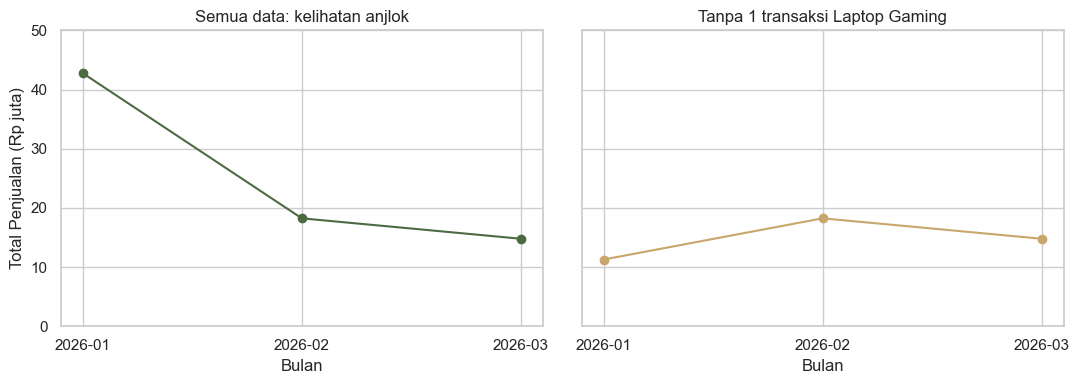

In [111]:
bulanan_tanpa = tanpa_laptop.groupby("bulan", as_index=False).agg(
    total_penjualan=("nilai_penjualan", "sum")
)
bulanan_tanpa["total_juta"] = bulanan_tanpa["total_penjualan"] / 1_000_000
bulanan_tanpa["pertumbuhan_%"] = (bulanan_tanpa["total_penjualan"].pct_change() * 100).round(1)

display(bulanan_tanpa[["bulan", "total_juta", "pertumbuhan_%"]])

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

kiri.plot(df_bulanan["bulan"], df_bulanan["total_juta"], marker="o", color=warna_utama)
kiri.set_title("Semua data: kelihatan anjlok")

kanan.plot(bulanan_tanpa["bulan"], bulanan_tanpa["total_juta"], marker="o", color=warna_sorot)
kanan.set_title("Tanpa 1 transaksi Laptop Gaming")

for ax in (kiri, kanan):
    ax.set_xlabel("Bulan")
    ax.set_ylim(0, 50)
kiri.set_ylabel("Total Penjualan (Rp juta)")

plt.tight_layout()
plt.show()

**Versi interaktif.** Dua garis dalam satu grafik supaya perbandingannya langsung terlihat. Klik nama di legend untuk menyembunyikan satu garis.

In [112]:
gabung = pd.concat([
    df_bulanan.assign(data="Semua data"),
    bulanan_tanpa.assign(data="Tanpa 1 transaksi Laptop Gaming"),
])

fig = px.line(gabung, x="bulan", y="total_juta", color="data", markers=True,
              range_y=[0, 50], title="Tren Penjualan Bulanan: Dengan vs Tanpa Laptop Gaming",
              color_discrete_sequence=[warna_utama, warna_sorot])
fig.update_xaxes(type="category")
fig.update_layout(xaxis_title="Bulan", yaxis_title="Total Penjualan (Rp juta)", legend_title="")
fig.show()

## 18. Menulis Insight

Rumusnya: **temuan data + makna bisnis + rekomendasi**. Angka di temuan diambil langsung dari tabel, bukan diketik manual.

In [113]:
elektronik = porsi[porsi["kategori"] == "Elektronik"].iloc[0]

print(f"Temuan: Elektronik menyumbang {elektronik['porsi_penjualan']:.1f}% penjualan, "
      f"tetapi hanya {elektronik['porsi_transaksi']:.1f}% dari jumlah transaksi.")
print("Makna bisnis: omzet sangat bergantung pada barang mahal yang jarang dibeli.")
print("Rekomendasi: jaga stok dan promosi Elektronik, sambil mendorong kategori lain "
      "yang transaksinya sering agar omzet tidak bertumpu pada satu kategori.")
print("Sumber: data-bersih.csv, periode Januari-Maret 2026, satuan rupiah.")

Temuan: Elektronik menyumbang 59.2% penjualan, tetapi hanya 18.6% dari jumlah transaksi.
Makna bisnis: omzet sangat bergantung pada barang mahal yang jarang dibeli.
Rekomendasi: jaga stok dan promosi Elektronik, sambil mendorong kategori lain yang transaksinya sering agar omzet tidak bertumpu pada satu kategori.
Sumber: data-bersih.csv, periode Januari-Maret 2026, satuan rupiah.


## 19. Simpan Grafik Jadi File

Berguna kalau grafik mau dipakai di laporan atau README proyek. Di Colab, filenya muncul di panel Files.

In [114]:
import os

plt.figure(figsize=(8, 4))
plt.barh(urut["kategori"], urut["total_juta"], color=warna)
plt.title("Total Penjualan per Kategori")
plt.xlabel("Total Penjualan (Rp juta)")
plt.ylabel("Kategori")
plt.savefig("grafik_penjualan_kategori.png", dpi=150, bbox_inches="tight")
plt.close()

print("Tersimpan:", os.path.exists("grafik_penjualan_kategori.png"))

Tersimpan: True


## 20. Latihan Gabungan

Pakai `data-bersih.csv`, kerjakan sendiri:

- Buat **bar chart** total `untung` per `kategori`, urut dari terbesar.

- Buat **line chart** jumlah transaksi per bulan.

- Tukar hasilnya dengan temanmu, lalu cek pakai checklist: judul jelas, label sumbu ada, satuan terbaca, warna tidak berlebihan, kesimpulan tidak melebihi bukti.

## 21. Persiapan Sesi 6

Sesi 6 dikerjakan di komputer sendiri, bukan di Colab. Kerjakan di rumah:

- Instal Python 3.13 dan VS Code (ekstensi Python).

- Di terminal VS Code: `python -m venv .venv`, aktifkan, lalu `pip install streamlit pandas numpy matplotlib seaborn plotly`.

- Cek berhasil dengan `streamlit hello`.

Panduan lengkap ada di `panduan-setup.md`.

## Cheatsheet: Matplotlib, Seaborn, Plotly

### Matplotlib (`import matplotlib.pyplot as plt`)

| Perintah | Fungsinya | Kapan dipakai |
|---|---|---|
| `plt.bar(x, y)` / `plt.barh(x, y)` | Batang tegak / mendatar | Membandingkan kategori (mendatar kalau nama panjang) |
| `plt.plot(x, y)` | Garis | Tren waktu |
| `plt.hist(data, bins=...)` | Histogram | Sebaran satu angka |
| `plt.scatter(x, y)` | Titik | Hubungan dua angka |
| `plt.pie(nilai, labels=..., autopct=...)` | Pie chart | Porsi 2–4 bagian |
| `plt.boxplot([a, b])` | Boxplot | Sebaran antar kelompok, outlier |
| `plt.title()` `plt.xlabel()` `plt.ylabel()` | Judul dan label sumbu | Selalu |
| `plt.legend()` | Keterangan warna/garis (butuh `label=`) | Lebih dari satu garis atau seri |
| `plt.figure(figsize=(w, h))` | Ukuran gambar | Grafik terlalu sempit atau terlalu lebar |
| `plt.subplots(1, 2)` | Beberapa grafik satu kertas | Membandingkan berdampingan |
| `plt.tight_layout()` | Merapikan jarak | Setelah `subplots` |
| `plt.xticks(rotation=...)` | Memiringkan label sumbu X | Label panjang |
| `plt.ylim(0, ...)` | Batas sumbu Y | Menjaga sumbu mulai dari 0 |
| `plt.grid()` | Garis bantu | Mempermudah membaca angka |
| `plt.savefig("a.png", dpi=150)` | Simpan jadi file | Dipakai di laporan atau README |
| `plt.show()` | Menampilkan grafik | Paling akhir |

### Seaborn (`import seaborn as sns`)

| Perintah | Fungsinya | Kapan dipakai |
|---|---|---|
| `sns.barplot(data=, x=, y=)` | Batang, tinggi = rata-rata | Rata-rata per kelompok |
| `sns.countplot(data=, x=)` | Batang, tinggi = jumlah baris | Menghitung frekuensi kategori |
| `sns.histplot(data, kde=True)` | Histogram + garis halus | Sebaran satu angka |
| `sns.boxplot(data=, x=, y=)` | Boxplot per kelompok | Sebaran antar kelompok, outlier |
| `sns.scatterplot(data=, x=, y=, hue=)` | Scatter, warna per kelompok | Hubungan dua angka |
| `sns.heatmap(tabel, annot=True)` | Tabel berwarna + angka | Pivot table, korelasi |
| `hue="kolom"` | Pecah per warna | Membandingkan kelompok |
| `palette="Set2"` | Pilihan warna | Mengganti warna |
| `sns.set_theme(style="whitegrid")` | Tampilan semua grafik | Sekali di awal |

### Plotly (`import plotly.express as px`)

| Perintah | Fungsinya | Kapan dipakai |
|---|---|---|
| `px.bar(df, x=, y=)` | Batang interaktif | Membandingkan kategori |
| `px.line(df, x=, y=, color=)` | Garis, satu per `color` | Tren banyak seri |
| `px.scatter(df, x=, y=, size=, hover_name=)` | Titik interaktif | Hubungan dua angka |
| `px.histogram(df, x=, nbins=)` | Histogram | Sebaran satu angka |
| `px.pie(names=, values=)` | Pie chart | Porsi 2–4 bagian |
| `fig.update_layout(title=, xaxis_title=)` | Judul, label, ukuran | Merapikan |
| `fig.update_traces(marker_color=)` | Warna isi grafik | Mengganti warna |
| `fig.write_html("a.html")` | Simpan jadi halaman web | Dibagikan, tetap interaktif |
| `fig.show()` | Menampilkan | Paling akhir |

### Kalau bingung memilih

| Pertanyaanmu | Grafik |
|---|---|
| Mana yang paling besar? | Bar chart |
| Naik atau turun? | Line chart |
| Angkanya menyebar bagaimana? | Histogram atau boxplot |
| Dua angka ini berhubungan tidak? | Scatter plot |
| Bagian-bagiannya berapa persen? | Pie chart (sedikit bagian) atau bar chart |
| Polanya di tabel dua dimensi? | Heatmap |

## Selesai

Hari ini: memilih grafik yang tepat, membuatnya di Matplotlib, Seaborn, dan Plotly, menghitung KPI, lalu mengubah temuan jadi insight. Minggu depan semua ini dirakit jadi dashboard Streamlit.